# E-Commerce Sales and Customer Analytics
## End-to-End Data Analytics Project
### Tools Used
- Excel
- Python
- NumPy
- Pandas
- Matplotlib
- SQL
- Power BI
## Project Objective

The objective of this project is to analyze e-commerce sales data to identify trends in sales, profit, customer behavior, product performance, regional performance, and the impact of discounts on profitability.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/raw/superstore.csv")

In [3]:
df.head()

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,Record Count,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,07-01-2011,CA-2011-130813,...,19,Consumer,09-01-2011,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,21-01-2011,CA-2011-148614,...,19,Consumer,26-01-2011,Standard Class,0.94,California,Paper,2011,North America,4
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,05-08-2011,CA-2011-118962,...,21,Consumer,09-08-2011,Standard Class,1.81,California,Paper,2011,North America,32
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,05-08-2011,CA-2011-118962,...,111,Consumer,09-08-2011,Standard Class,4.59,California,Paper,2011,North America,32
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,29-09-2011,CA-2011-146969,...,6,Consumer,03-10-2011,Standard Class,1.32,California,Paper,2011,North America,40


In [4]:
df.shape

(51290, 27)

In [5]:
df.columns

Index(['Category', 'City', 'Country', 'Customer.ID', 'Customer.Name',
       'Discount', 'Market', 'Record Count', 'Order.Date', 'Order.ID',
       'Order.Priority', 'Product.ID', 'Product.Name', 'Profit', 'Quantity',
       'Region', 'Row.ID', 'Sales', 'Segment', 'Ship.Date', 'Ship.Mode',
       'Shipping.Cost', 'State', 'Sub.Category', 'Year', 'Market2', 'weeknum'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        51290 non-null  str    
 1   City            51290 non-null  str    
 2   Country         51290 non-null  str    
 3   Customer.ID     51290 non-null  str    
 4   Customer.Name   51290 non-null  str    
 5   Discount        51290 non-null  float64
 6   Market          51290 non-null  str    
 7   Record Count    51290 non-null  int64  
 8   Order.Date      51290 non-null  str    
 9   Order.ID        51290 non-null  str    
 10  Order.Priority  51290 non-null  str    
 11  Product.ID      51290 non-null  str    
 12  Product.Name    51290 non-null  str    
 13  Profit          51290 non-null  float64
 14  Quantity        51290 non-null  int64  
 15  Region          51290 non-null  str    
 16  Row.ID          51290 non-null  int64  
 17  Sales           51290 non-null  int64  
 1

In [7]:
df.describe()

,Discount,Record Count,Profit,Quantity,Row.ID,Sales,Shipping.Cost,Year,weeknum
count,51290.000000,51290.0,51290.000000,51290.000000,51290.00000,51290.000000,51290.000000,51290.000000,51290.000000
mean,0.142908,1.0,28.610982,3.476545,25645.50000,246.498440,26.375818,2012.777208,31.287112
std,0.212280,0.0,174.340972,2.278766,14806.29199,487.567175,57.296810,1.098931,14.429795
min,0.000000,1.0,-6599.978000,1.000000,1.00000,0.000000,0.002000,2011.000000,1.000000
25%,0.000000,1.0,0.000000,2.000000,12823.25000,31.000000,2.610000,2012.000000,20.000000
50%,0.000000,1.0,9.240000,3.000000,25645.50000,85.000000,7.790000,2013.000000,33.000000
75%,0.200000,1.0,36.810000,5.000000,38467.75000,251.000000,24.450000,2014.000000,44.000000
max,0.850000,1.0,8399.976000,14.000000,51290.00000,22638.000000,933.570000,2014.000000,53.000000


### Key Observations

- The dataset contains 51,290 records with no missing values in numerical columns.
- The Sales column appears to be right-skewed, as the mean sales value is significantly higher than the median.
- Some transactions have negative profit, indicating losses.
- Quantity values range from 1 to 14, with no zero or negative values.
- Discounts range from 0% to 85%, which may significantly impact profitability.
- Shipping costs show a wide range and may require further analysis.

In [8]:
df.nunique()

Category              3
City               3636
Country             147
Customer.ID        4873
Customer.Name       795
Discount             27
Market                7
Record Count          1
Order.Date         1430
Order.ID          25035
Order.Priority        4
Product.ID        10292
Product.Name       3788
Profit            24575
Quantity             14
Region               13
Row.ID            51290
Sales              2246
Segment               3
Ship.Date          1464
Ship.Mode             4
Shipping.Cost     16877
State              1094
Sub.Category         17
Year                  4
Market2               6
weeknum              53
dtype: int64

### Dataset Structure Summary

- The dataset contains 3 main product categories and 17 sub-categories.
- There are 25,035 unique orders across 51,290 transaction records.
- The dataset contains 4,873 unique customer IDs and 3,788 unique product names.
- The data covers 147 countries, 13 regions, and 7 markets.
- The dataset spans 4 years from 2011 to 2014.
- Some columns such as Record Count, Row.ID, Market2, Year, and weeknum require further investigation.

## 2. Data Cleaning

In [9]:
df.isnull().sum()

Category          0
City              0
Country           0
Customer.ID       0
Customer.Name     0
Discount          0
Market            0
Record Count      0
Order.Date        0
Order.ID          0
Order.Priority    0
Product.ID        0
Product.Name      0
Profit            0
Quantity          0
Region            0
Row.ID            0
Sales             0
Segment           0
Ship.Date         0
Ship.Mode         0
Shipping.Cost     0
State             0
Sub.Category      0
Year              0
Market2           0
weeknum           0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df[["Order.Date","Ship.Date"]].head()

,Order.Date,Ship.Date
0,07-01-2011,09-01-2011
1,21-01-2011,26-01-2011
2,05-08-2011,09-08-2011
3,05-08-2011,09-08-2011
4,29-09-2011,03-10-2011


In [12]:
df["Order.Date"] = pd.to_datetime(
    df["Order.Date"],
    format = "%d-%m-%Y"
)

In [13]:
df["Ship.Date"] = pd.to_datetime(
    df["Ship.Date"],
    format = "%d-%m-%Y"
)

In [14]:
df[["Order.Date","Ship.Date"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order.Date  51290 non-null  datetime64[us]
 1   Ship.Date   51290 non-null  datetime64[us]
dtypes: datetime64[us](2)
memory usage: 801.5 KB


In [15]:
df[["Order.Date","Ship.Date"]].head()

,Order.Date,Ship.Date
0,2011-01-07,2011-01-09
1,2011-01-21,2011-01-26
2,2011-08-05,2011-08-09
3,2011-08-05,2011-08-09
4,2011-09-29,2011-10-03


In [16]:
df["Record Count"].value_counts()

Record Count
1    51290
Name: count, dtype: int64

In [17]:
df["Market2"].value_counts()

Market2
APAC             11002
North America    10378
LATAM            10294
EU               10000
EMEA              5029
Africa            4587
Name: count, dtype: int64

In [18]:
df[['Order.Date', 'Year', 'weeknum']].head(10)

,Order.Date,Year,weeknum
0,2011-01-07,2011,2
1,2011-01-21,2011,4
2,2011-08-05,2011,32
3,2011-08-05,2011,32
4,2011-09-29,2011,40
5,2011-10-19,2011,43
6,2011-11-04,2011,45
7,2011-11-12,2011,46
8,2011-11-22,2011,48
9,2011-12-05,2011,50


In [19]:
df['Year'].value_counts().sort_index()

Year
2011     8998
2012    10962
2013    13799
2014    17531
Name: count, dtype: int64

In [20]:
(df['Order.Date'].dt.year == df['Year']).all()

np.True_

In [21]:
df['Order.Date'].dt.isocalendar().week.equals(
    df['weeknum'].astype('UInt32')
)

False

In [22]:
comparison = pd.DataFrame({
    'Order.Date': df['Order.Date'],
    'Existing_weeknum': df['weeknum'],
    'ISO_week': df['Order.Date'].dt.isocalendar().week
})

comparison.head(20)

,Order.Date,Existing_weeknum,ISO_week
0,2011-01-07,2,1
1,2011-01-21,4,3
2,2011-08-05,32,31
3,2011-08-05,32,31
4,2011-09-29,40,39
5,2011-10-19,43,42
6,2011-11-04,45,44
7,2011-11-12,46,45
8,2011-11-22,48,47
9,2011-12-05,50,49


In [23]:
comparison[comparison['Existing_weeknum'] != comparison['ISO_week']].head(10)

,Order.Date,Existing_weeknum,ISO_week
0,2011-01-07,2,1
1,2011-01-21,4,3
2,2011-08-05,32,31
3,2011-08-05,32,31
4,2011-09-29,40,39
5,2011-10-19,43,42
6,2011-11-04,45,44
7,2011-11-12,46,45
8,2011-11-22,48,47
9,2011-12-05,50,49


In [24]:
df = df.drop(columns=['Record Count', 'Year', 'weeknum'])

In [25]:
df.shape

(51290, 24)

In [26]:
df.columns = df.columns.str.replace('.', '_', regex=False)

In [27]:
df.columns

Index(['Category', 'City', 'Country', 'Customer_ID', 'Customer_Name',
       'Discount', 'Market', 'Order_Date', 'Order_ID', 'Order_Priority',
       'Product_ID', 'Product_Name', 'Profit', 'Quantity', 'Region', 'Row_ID',
       'Sales', 'Segment', 'Ship_Date', 'Ship_Mode', 'Shipping_Cost', 'State',
       'Sub_Category', 'Market2'],
      dtype='str')

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Category        51290 non-null  str           
 1   City            51290 non-null  str           
 2   Country         51290 non-null  str           
 3   Customer_ID     51290 non-null  str           
 4   Customer_Name   51290 non-null  str           
 5   Discount        51290 non-null  float64       
 6   Market          51290 non-null  str           
 7   Order_Date      51290 non-null  datetime64[us]
 8   Order_ID        51290 non-null  str           
 9   Order_Priority  51290 non-null  str           
 10  Product_ID      51290 non-null  str           
 11  Product_Name    51290 non-null  str           
 12  Profit          51290 non-null  float64       
 13  Quantity        51290 non-null  int64         
 14  Region          51290 non-null  str           
 15  Row_ID       

In [29]:
df.head()

,Category,City,Country,Customer_ID,Customer_Name,Discount,Market,Order_Date,Order_ID,Order_Priority,...,Region,Row_ID,Sales,Segment,Ship_Date,Ship_Mode,Shipping_Cost,State,Sub_Category,Market2
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,2011-01-07,CA-2011-130813,High,...,West,36624,19,Consumer,2011-01-09,Second Class,4.37,California,Paper,North America
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,2011-01-21,CA-2011-148614,Medium,...,West,37033,19,Consumer,2011-01-26,Standard Class,0.94,California,Paper,North America
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,2011-08-05,CA-2011-118962,Medium,...,West,31468,21,Consumer,2011-08-09,Standard Class,1.81,California,Paper,North America
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,2011-08-05,CA-2011-118962,Medium,...,West,31469,111,Consumer,2011-08-09,Standard Class,4.59,California,Paper,North America
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,2011-09-29,CA-2011-146969,High,...,West,32440,6,Consumer,2011-10-03,Standard Class,1.32,California,Paper,North America


### Data Cleaning Summary

The dataset was checked for missing values and duplicate records, and none were found. The Order_Date and Ship_Date columns were converted from string format to datetime format. Unnecessary or redundant columns, including Record Count, Year, and weeknum, were removed. Column names were standardized by replacing dots with underscores to make them easier to use in Python and SQL.

## 3. Feature Engineering

In this section, new features are created from the existing dataset to support time-based analysis, shipping analysis, and profitability analysis.

In [30]:
df['Order_Year'] = df['Order_Date'].dt.year

In [31]:
df[['Order_Date', 'Order_Year']].head()

,Order_Date,Order_Year
0,2011-01-07,2011
1,2011-01-21,2011
2,2011-08-05,2011
3,2011-08-05,2011
4,2011-09-29,2011


In [32]:
df['Order_Month'] = df['Order_Date'].dt.month

In [33]:
df[['Order_Date', 'Order_Year', 'Order_Month']].head()

,Order_Date,Order_Year,Order_Month
0,2011-01-07,2011,1
1,2011-01-21,2011,1
2,2011-08-05,2011,8
3,2011-08-05,2011,8
4,2011-09-29,2011,9


In [34]:
df['Month_Name'] = df['Order_Date'].dt.month_name()

In [35]:
df[['Order_Date', 'Order_Month', 'Month_Name']].head()

,Order_Date,Order_Month,Month_Name
0,2011-01-07,1,January
1,2011-01-21,1,January
2,2011-08-05,8,August
3,2011-08-05,8,August
4,2011-09-29,9,September


In [36]:
df['Order_Quarter'] = 'Q' + df['Order_Date'].dt.quarter.astype(str)

In [37]:
df[['Order_Date', 'Order_Month', 'Month_Name', 'Order_Quarter']].head(10)

,Order_Date,Order_Month,Month_Name,Order_Quarter
0,2011-01-07,1,January,Q1
1,2011-01-21,1,January,Q1
2,2011-08-05,8,August,Q3
3,2011-08-05,8,August,Q3
4,2011-09-29,9,September,Q3
5,2011-10-19,10,October,Q4
6,2011-11-04,11,November,Q4
7,2011-11-12,11,November,Q4
8,2011-11-22,11,November,Q4
9,2011-12-05,12,December,Q4


In [38]:
df['Shipping_Days'] = (df['Ship_Date'] - df['Order_Date']).dt.days

In [39]:
df[['Order_Date', 'Ship_Date', 'Shipping_Days']].head()

,Order_Date,Ship_Date,Shipping_Days
0,2011-01-07,2011-01-09,2
1,2011-01-21,2011-01-26,5
2,2011-08-05,2011-08-09,4
3,2011-08-05,2011-08-09,4
4,2011-09-29,2011-10-03,4


In [40]:
df['Profit_Margin'] = np.where(
    df['Sales'] != 0,
    (df['Profit'] / df['Sales']) * 100,
    0
)

In [41]:
df[['Sales', 'Profit', 'Profit_Margin']].head()

,Sales,Profit,Profit_Margin
0,19,9.3312,49.111579
1,19,9.2928,48.909474
2,21,9.8418,46.865714
3,111,53.2608,47.982703
4,6,3.1104,51.840000


In [42]:
df[['Order_Year', 'Order_Month', 'Month_Name',
    'Order_Quarter', 'Shipping_Days', 'Profit_Margin']].head()

,Order_Year,Order_Month,Month_Name,Order_Quarter,Shipping_Days,Profit_Margin
0,2011,1,January,Q1,2,49.111579
1,2011,1,January,Q1,5,48.909474
2,2011,8,August,Q3,4,46.865714
3,2011,8,August,Q3,4,47.982703
4,2011,9,September,Q3,4,51.840000


### Feature Engineering Summary

New features were created to support time-based, shipping, and profitability analysis. These include Order_Year, Order_Month, Month_Name, Order_Quarter, Shipping_Days, and Profit_Margin.

## 4. NumPy Analysis

NumPy is used to perform numerical analysis on key business metrics such as Sales, Profit, Quantity, and Shipping Days.

In [43]:
sales_array = df['Sales'].to_numpy()

sales_stats = {
    'Mean Sales': np.mean(sales_array),
    'Median Sales': np.median(sales_array),
    'Standard Deviation': np.std(sales_array),
    'Minimum Sales': np.min(sales_array),
    'Maximum Sales': np.max(sales_array),
    '25th Percentile': np.percentile(sales_array, 25),
    '75th Percentile': np.percentile(sales_array, 75)
}

sales_stats

{'Mean Sales': np.float64(246.49844024176252),
 'Median Sales': np.float64(85.0),
 'Standard Deviation': np.float64(487.5624215651815),
 'Minimum Sales': np.int64(0),
 'Maximum Sales': np.int64(22638),
 '25th Percentile': np.float64(31.0),
 '75th Percentile': np.float64(251.0)}

### Sales Analysis Insights

- The average sales value is 246.50, while the median sales value is 85.
- The difference between mean and median indicates that the sales distribution is likely right-skewed.
- Sales values show high variability, with a standard deviation of 487.56.
- A small number of high-value transactions significantly increase the overall average sales.

In [44]:
profit_array = df['Profit'].to_numpy()

profit_stats = {
    'Mean Profit': np.mean(profit_array),
    'Median Profit': np.median(profit_array),
    'Standard Deviation': np.std(profit_array),
    'Minimum Profit': np.min(profit_array),
    'Maximum Profit': np.max(profit_array),
    'Loss Making Transactions': np.sum(profit_array < 0),
    'Profitable Transactions': np.sum(profit_array > 0)
}

profit_stats

{'Mean Profit': np.float64(28.610982477675964),
 'Median Profit': np.float64(9.24),
 'Standard Deviation': np.float64(174.33927233070466),
 'Minimum Profit': np.float64(-6599.978),
 'Maximum Profit': np.float64(8399.976),
 'Loss Making Transactions': np.int64(12544),
 'Profitable Transactions': np.int64(38078)}

In [45]:
np.sum(profit_array < 0)

np.int64(12544)

In [46]:
np.sum(profit_array > 0)

np.int64(38078)

### Profit Analysis Insights

- The average profit is 28.61, while the median profit is 9.24, indicating a right-skewed profit distribution.
- There are 12,544 loss-making transactions, representing approximately 24.46% of all transactions.
- Profit values range from -6,599.98 to 8,399.98, indicating significant variation in transaction profitability.
- Further analysis is required to identify the factors contributing to loss-making transactions.

In [47]:
quantity_array = df['Quantity'].to_numpy()
shipping_array = df['Shipping_Days'].to_numpy()

operations_stats = {
    'Average Quantity per Transaction': np.mean(quantity_array),
    'Median Quantity': np.median(quantity_array),
    'Maximum Quantity': np.max(quantity_array),
    'Average Shipping Days': np.mean(shipping_array),
    'Minimum Shipping Days': np.min(shipping_array),
    'Maximum Shipping Days': np.max(shipping_array)
}

operations_stats

{'Average Quantity per Transaction': np.float64(3.4765451355039967),
 'Median Quantity': np.float64(3.0),
 'Maximum Quantity': np.int64(14),
 'Average Shipping Days': np.float64(3.96937024761162),
 'Minimum Shipping Days': np.int64(0),
 'Maximum Shipping Days': np.int64(7)}

### Quantity and Shipping Insights

- The average quantity per transaction is approximately 3.48 items, with a median quantity of 3.
- The maximum quantity purchased in a transaction is 14 items.
- The average shipping duration is approximately 4 days.
- Shipping duration ranges from 0 to 7 days.

## 5. Exploratory Data Analysis (EDA)

This section explores the dataset to identify sales trends, profitability patterns, customer behavior, product performance, and geographical insights.

### 5.1 Category Performance

This analysis identifies which product categories generate the highest sales and profit.

In [48]:
category_analysis = df.groupby('Category')[['Sales', 'Profit']].sum().sort_values(
    by='Sales',
    ascending=False
)

category_analysis

,Sales,Profit
Category,,
Technology,4744691,663778.73318
Furniture,4110884,285204.72380
Office Supplies,3787330,518473.83430


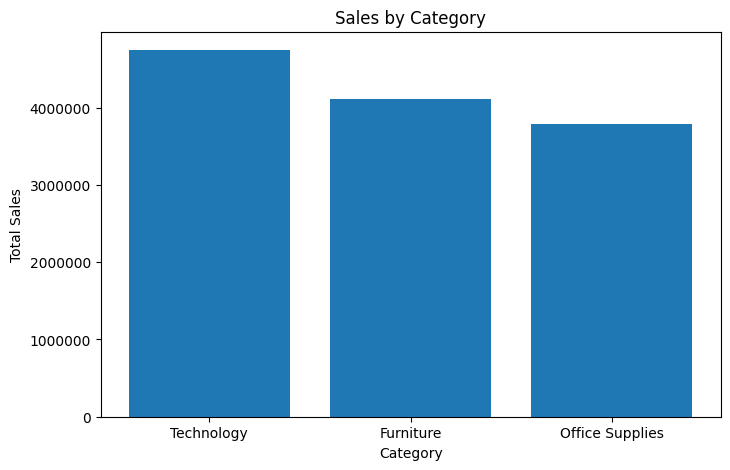

In [50]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_analysis.index,
    category_analysis['Sales']
)

plt.title('Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')

plt.ticklabel_format(style='plain', axis='y')

plt.show()

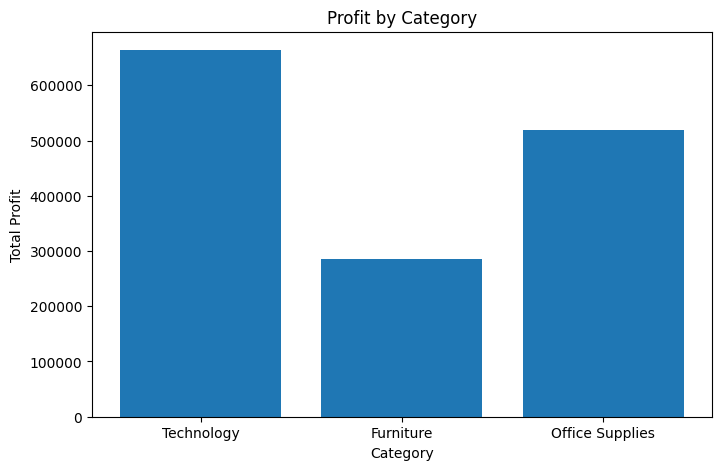

In [51]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_analysis.index,
    category_analysis['Profit']
)

plt.title('Profit by Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')

plt.ticklabel_format(style='plain', axis='y')

plt.show()

### 5.2 Sub-Category Performance

This analysis identifies the best-performing and least-profitable product sub-categories based on sales and profit.

In [52]:
subcategory_analysis = df.groupby('Sub_Category')[['Sales', 'Profit']].sum().sort_values(
    by='Sales',
    ascending=False
)

subcategory_analysis

,Sales,Profit
Sub_Category,,
Phones,1706874,216717.00580
Copiers,1509439,258567.54818
Chairs,1501682,140396.26750
Bookcases,1466559,161924.41950
Storage,1127124,108461.48980
Appliances,1011081,141680.58940
Machines,779071,58867.87300
Tables,757034,-64083.38870
Accessories,749307,129626.30620


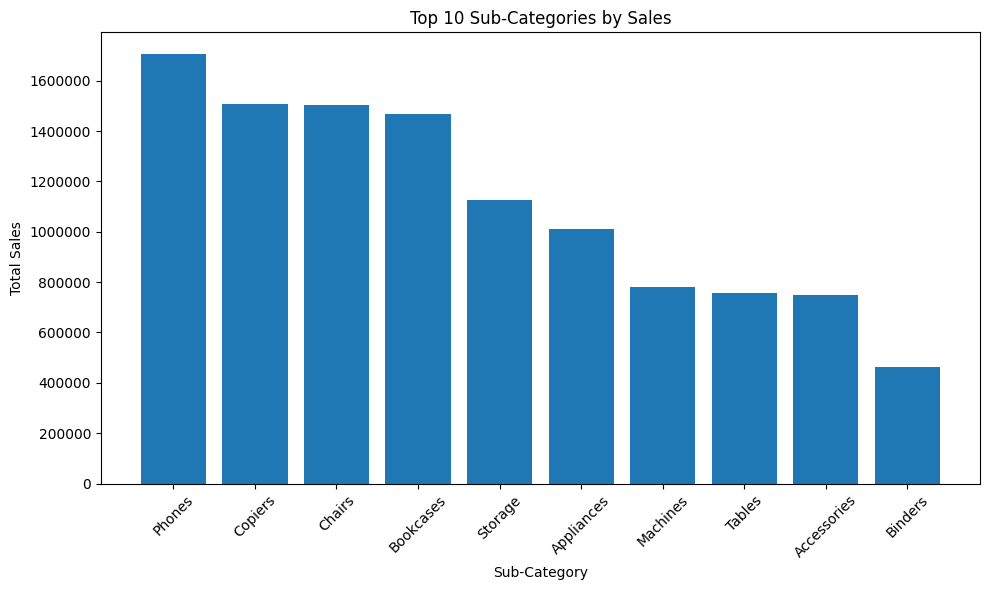

In [53]:
top10_subcategory_sales = subcategory_analysis.head(10)

plt.figure(figsize=(10, 6))

plt.bar(
    top10_subcategory_sales.index,
    top10_subcategory_sales['Sales']
)

plt.title('Top 10 Sub-Categories by Sales')
plt.xlabel('Sub-Category')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)

plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()

plt.show()

In [54]:
subcategory_profit = df.groupby('Sub_Category')['Profit'].sum().sort_values(
    ascending=False
)

subcategory_profit

Sub_Category
Copiers        258567.54818
Phones         216717.00580
Bookcases      161924.41950
Appliances     141680.58940
Chairs         140396.26750
Accessories    129626.30620
Storage        108461.48980
Binders         72449.84600
Paper           59207.68270
Machines        58867.87300
Art             57953.91090
Furnishings     46967.42550
Envelopes       29601.11630
Supplies        22583.26310
Labels          15010.51200
Fasteners       11525.42410
Tables         -64083.38870
Name: Profit, dtype: float64

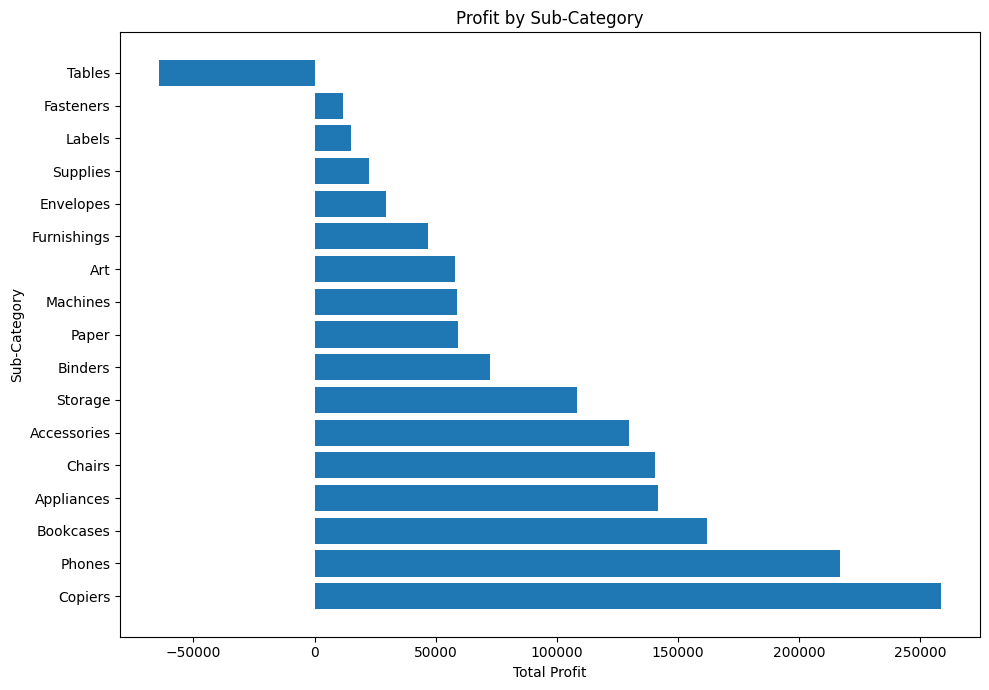

In [55]:
plt.figure(figsize=(10, 7))

plt.barh(
    subcategory_profit.index,
    subcategory_profit.values
)

plt.title('Profit by Sub-Category')
plt.xlabel('Total Profit')
plt.ylabel('Sub-Category')

plt.ticklabel_format(style='plain', axis='x')

plt.tight_layout()

plt.show()

### 5.3 Yearly Sales and Profit Trends

This analysis examines how sales and profit changed over the years to identify business growth trends.

In [56]:
yearly_analysis = df.groupby('Order_Year')[['Sales', 'Profit']].sum()

yearly_analysis

,Sales,Profit
Order_Year,,
2011,2259511,248940.81154
2012,2677493,307415.27910
2013,3405860,406935.23018
2014,4300041,504165.97046


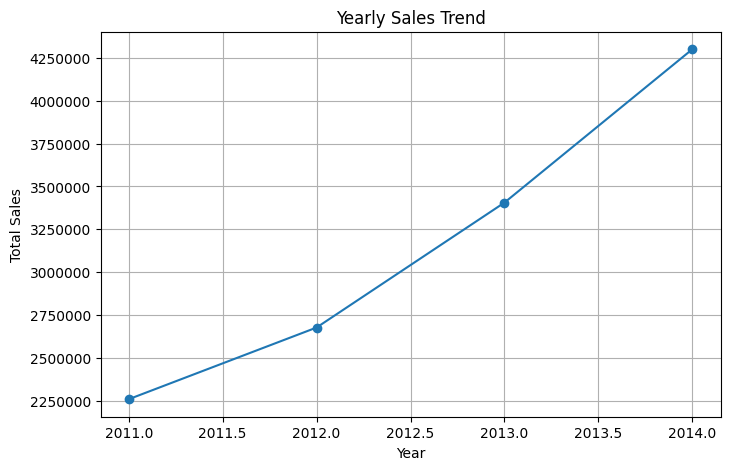

In [57]:
plt.figure(figsize=(8, 5))

plt.plot(
    yearly_analysis.index,
    yearly_analysis['Sales'],
    marker='o'
)

plt.title('Yearly Sales Trend')
plt.xlabel('Year')
plt.ylabel('Total Sales')

plt.ticklabel_format(style='plain', axis='y')

plt.grid()

plt.show()

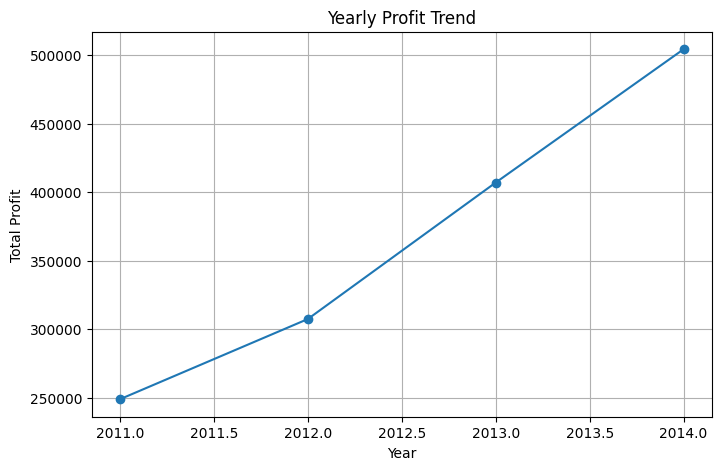

In [58]:
plt.figure(figsize=(8, 5))

plt.plot(
    yearly_analysis.index,
    yearly_analysis['Profit'],
    marker='o'
)

plt.title('Yearly Profit Trend')
plt.xlabel('Year')
plt.ylabel('Total Profit')

plt.ticklabel_format(style='plain', axis='y')

plt.grid()

plt.show()

### 5.4 Monthly Sales Trend

This analysis identifies monthly sales patterns and helps understand seasonal trends across the business.

In [59]:
monthly_sales = df.groupby(
    ['Order_Month', 'Month_Name']
)['Sales'].sum().reset_index()

monthly_sales

,Order_Month,Month_Name,Sales
0,1,January,675141
1,2,February,543768
2,3,March,770519
3,4,April,698603
4,5,May,904061
5,6,June,1269751
6,7,July,749423
7,8,August,1293852
8,9,September,1437432
9,10,October,1168220


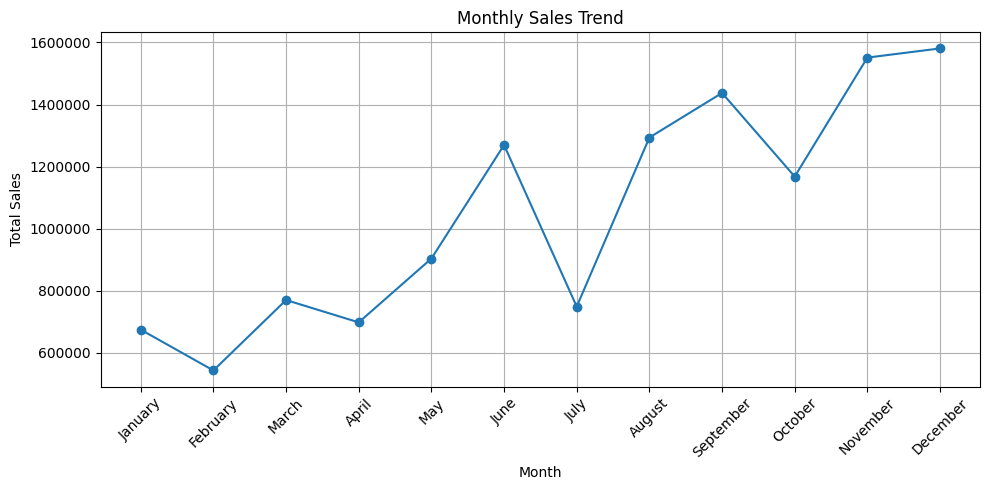

In [63]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales['Month_Name'],
    monthly_sales['Sales'],
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)

plt.ticklabel_format(style='plain', axis='y')

plt.grid()

plt.tight_layout()

plt.show()

### 5.5 Regional Performance

This analysis evaluates sales and profit performance across different geographical regions.

In [64]:
region_analysis = df.groupby('Region')[['Sales', 'Profit']].sum().sort_values(
    by='Sales',
    ascending=False
)

region_analysis

,Sales,Profit
Region,,
Central,2822399,311403.98164
South,1600960,140355.76618
North,1248192,194597.95252
Oceania,1100207,120089.11200
Southeast Asia,884438,17852.32900
North Asia,848349,165578.42100
EMEA,806184,43897.97100
Africa,783776,88871.63100
Central Asia,752839,132480.18700


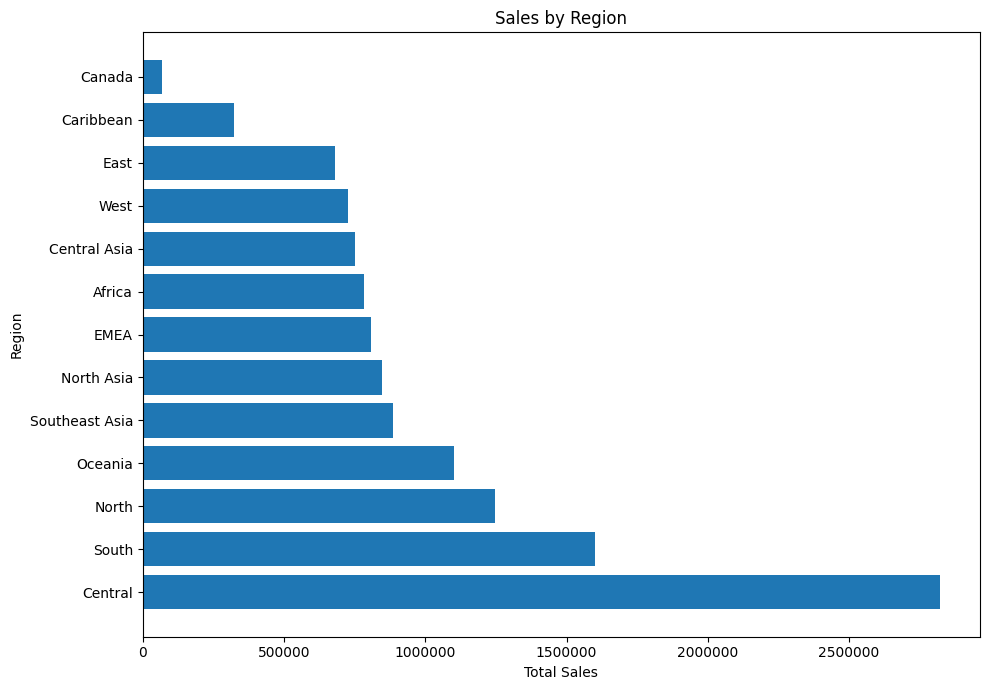

In [65]:
plt.figure(figsize=(10, 7))

plt.barh(
    region_analysis.index,
    region_analysis['Sales']
)

plt.title('Sales by Region')
plt.xlabel('Total Sales')
plt.ylabel('Region')

plt.ticklabel_format(style='plain', axis='x')

plt.tight_layout()

plt.show()

In [66]:
region_profit = df.groupby('Region')['Profit'].sum().sort_values(
    ascending=False
)

region_profit

Region
Central           311403.98164
North             194597.95252
North Asia        165578.42100
South             140355.76618
Central Asia      132480.18700
Oceania           120089.11200
West              108418.44890
East               91522.78000
Africa             88871.63100
EMEA               43897.97100
Caribbean          34571.32104
Southeast Asia     17852.32900
Canada             17817.39000
Name: Profit, dtype: float64

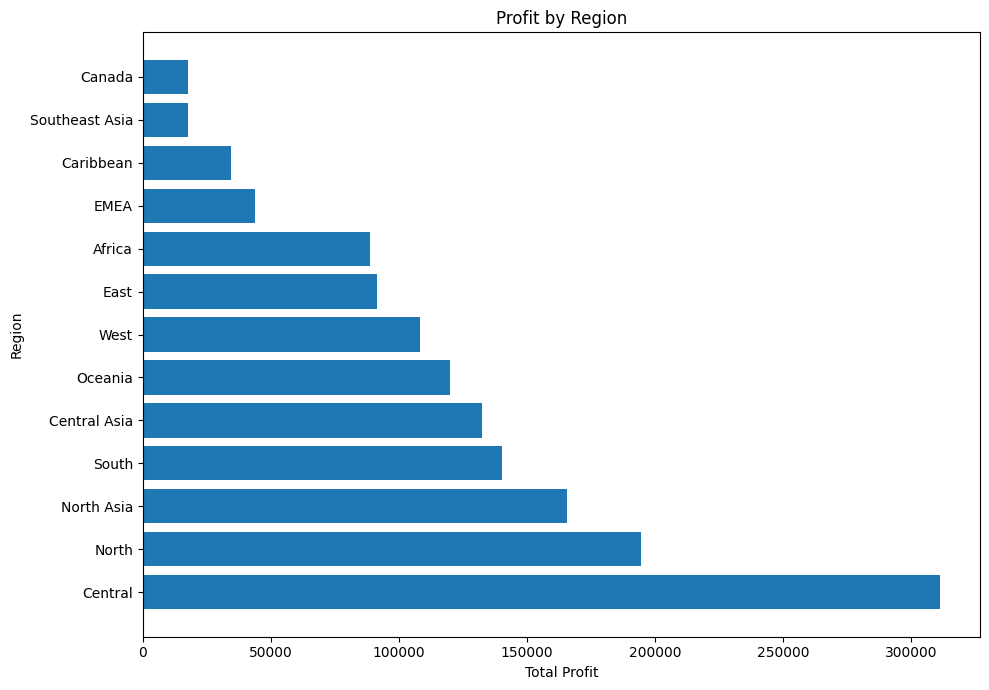

In [67]:
plt.figure(figsize=(10, 7))

plt.barh(
    region_profit.index,
    region_profit.values
)

plt.title('Profit by Region')
plt.xlabel('Total Profit')
plt.ylabel('Region')

plt.ticklabel_format(style='plain', axis='x')

plt.tight_layout()

plt.show()

### 5.6 Market Performance

This analysis evaluates sales and profit performance across different global markets.

In [68]:
market_analysis = df.groupby('Market')[['Sales', 'Profit']].sum().sort_values(
    by='Sales',
    ascending=False
)

market_analysis

,Sales,Profit
Market,,
APAC,3585833,436000.04900
EU,2938139,372829.74150
US,2297354,286397.02170
LATAM,2164687,221643.48708
EMEA,806184,43897.97100
Africa,783776,88871.63100
Canada,66932,17817.39000


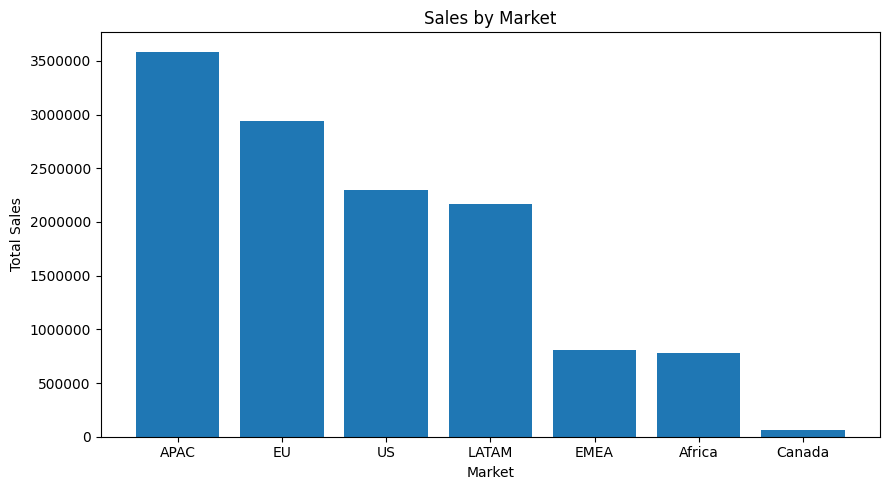

In [69]:
plt.figure(figsize=(9, 5))

plt.bar(
    market_analysis.index,
    market_analysis['Sales']
)

plt.title('Sales by Market')
plt.xlabel('Market')
plt.ylabel('Total Sales')

plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()

plt.show()

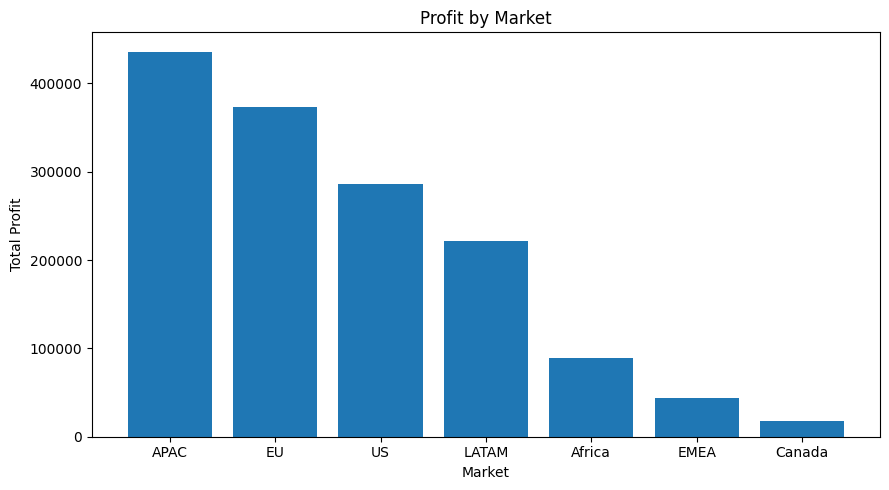

In [70]:
market_profit = df.groupby('Market')['Profit'].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    market_profit.index,
    market_profit.values
)

plt.title('Profit by Market')
plt.xlabel('Market')
plt.ylabel('Total Profit')

plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()

plt.show()

### 5.7 Top Customers Analysis

This analysis identifies the highest-value customers based on their total sales and profit contribution.

In [71]:
top_customers_sales = df.groupby('Customer_Name')[['Sales', 'Profit']].sum().sort_values(
    by='Sales',
    ascending=False
).head(10)

top_customers_sales

,Sales,Profit
Customer_Name,,
Tom Ashbrook,40489,6311.97910
Tamara Chand,37453,8672.89890
Greg Tran,35552,5214.13118
Christopher Conant,35187,5603.33370
Sean Miller,35170,-409.70634
Bart Watters,32315,3595.88590
Natalie Fritzler,31778,1542.82110
Fred Hopkins,30404,4609.29112
Jane Waco,30288,6265.84570


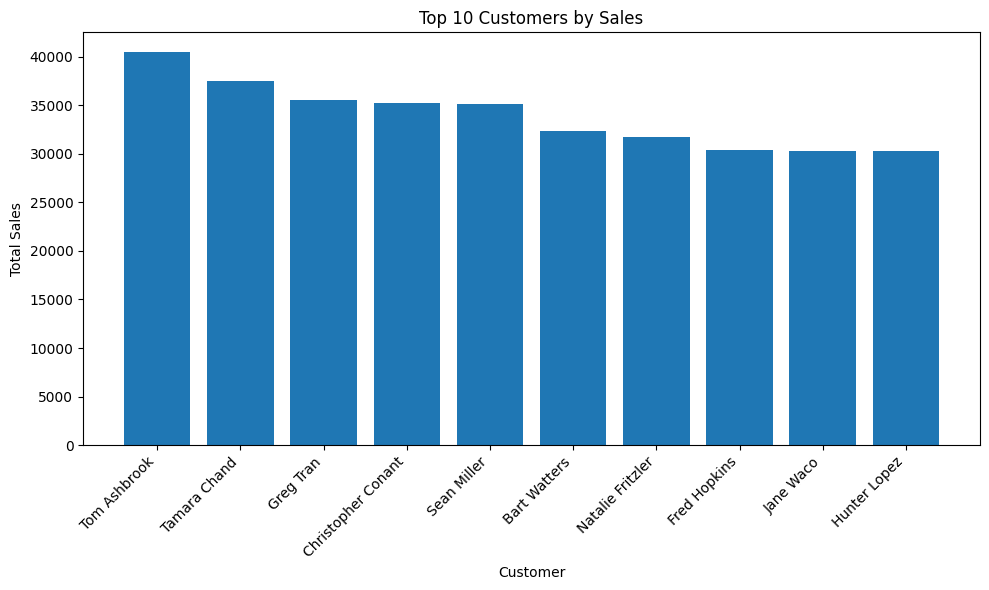

In [72]:
plt.figure(figsize=(10, 6))

plt.bar(
    top_customers_sales.index,
    top_customers_sales['Sales']
)

plt.title('Top 10 Customers by Sales')
plt.xlabel('Customer')
plt.ylabel('Total Sales')

plt.xticks(rotation=45, ha='right')

plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()

plt.show()

In [73]:
top_customers_profit = df.groupby('Customer_Name')[['Sales', 'Profit']].sum().sort_values(
    by='Profit',
    ascending=False
).head(10)

top_customers_profit

,Sales,Profit
Customer_Name,,
Tamara Chand,37453,8672.89890
Raymond Buch,29601,8453.04950
Sanjit Chand,26524,8205.37990
Hunter Lopez,30246,7816.56778
Bill Eplett,28480,7410.00530
Harry Marie,28477,6958.28640
Susan Pistek,29020,6484.40726
Mike Gockenbach,23378,6458.67620
Adrian Barton,25125,6417.28450


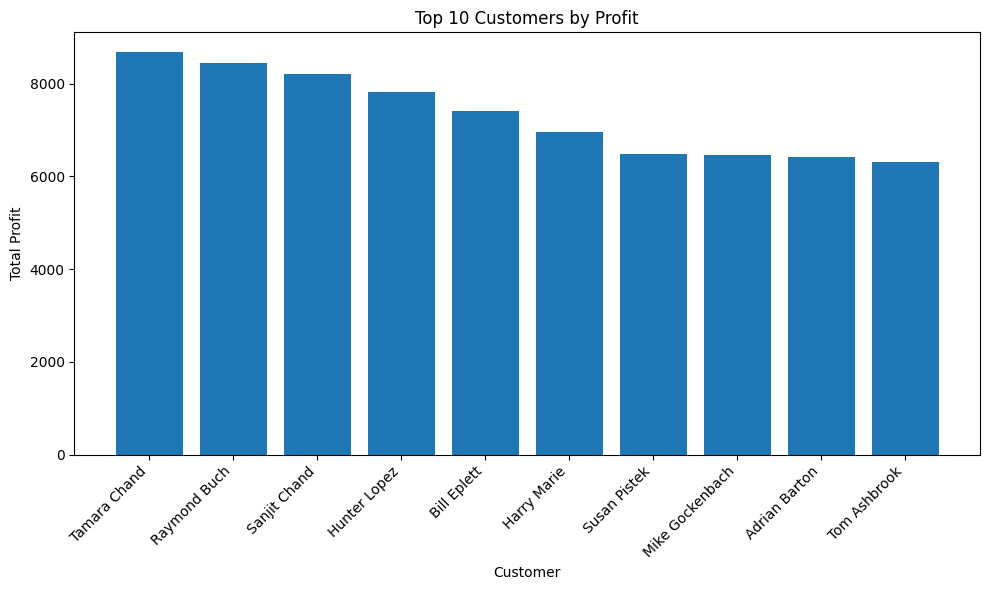

In [74]:
plt.figure(figsize=(10, 6))

plt.bar(
    top_customers_profit.index,
    top_customers_profit['Profit']
)

plt.title('Top 10 Customers by Profit')
plt.xlabel('Customer')
plt.ylabel('Total Profit')

plt.xticks(rotation=45, ha='right')

plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()

plt.show()

### 5.8 Top Products Analysis

This analysis identifies the best-performing products based on total sales and profit.

In [75]:
top_products_sales = df.groupby('Product_Name')[['Sales', 'Profit']].sum().sort_values(
    by='Sales',
    ascending=False
).head(10)

top_products_sales

,Sales,Profit
Product_Name,,
"Apple Smart Phone, Full Size",86936,5921.5786
"Cisco Smart Phone, Full Size",76441,17238.5206
"Motorola Smart Phone, Full Size",73159,17027.1130
"Nokia Smart Phone, Full Size",71904,9938.1955
Canon imageCLASS 2200 Advanced Copier,61600,25199.9280
"Hon Executive Leather Armchair, Adjustable",58200,5997.2541
"Office Star Executive Leather Armchair, Adjustable",50667,4710.9840
"Harbour Creations Executive Leather Armchair, Adjustable",50120,10427.3260
"Samsung Smart Phone, Cordless",48654,-198.0900


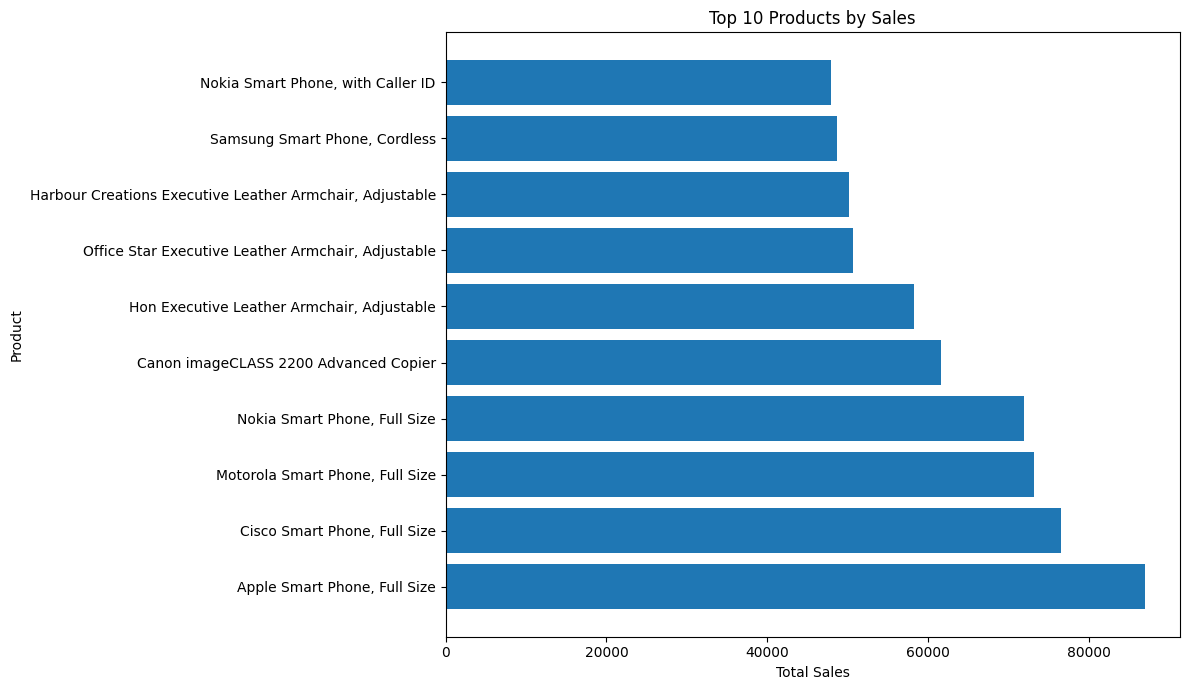

In [76]:
plt.figure(figsize=(12, 7))

plt.barh(
    top_products_sales.index,
    top_products_sales['Sales']
)

plt.title('Top 10 Products by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product')

plt.ticklabel_format(style='plain', axis='x')

plt.tight_layout()

plt.show()

In [77]:
top_products_profit = df.groupby('Product_Name')[['Sales', 'Profit']].sum().sort_values(
    by='Profit',
    ascending=False
).head(10)

top_products_profit

,Sales,Profit
Product_Name,,
Canon imageCLASS 2200 Advanced Copier,61600,25199.9280
"Cisco Smart Phone, Full Size",76441,17238.5206
"Motorola Smart Phone, Full Size",73159,17027.1130
"Hoover Stove, Red",31664,11807.9690
"Sauder Classic Bookcase, Traditional",39110,10672.0730
"Harbour Creations Executive Leather Armchair, Adjustable",50120,10427.3260
"Nokia Smart Phone, Full Size",71904,9938.1955
"Cisco Smart Phone, with Caller ID",43124,9786.6408
"Nokia Smart Phone, with Caller ID",47880,9465.3257


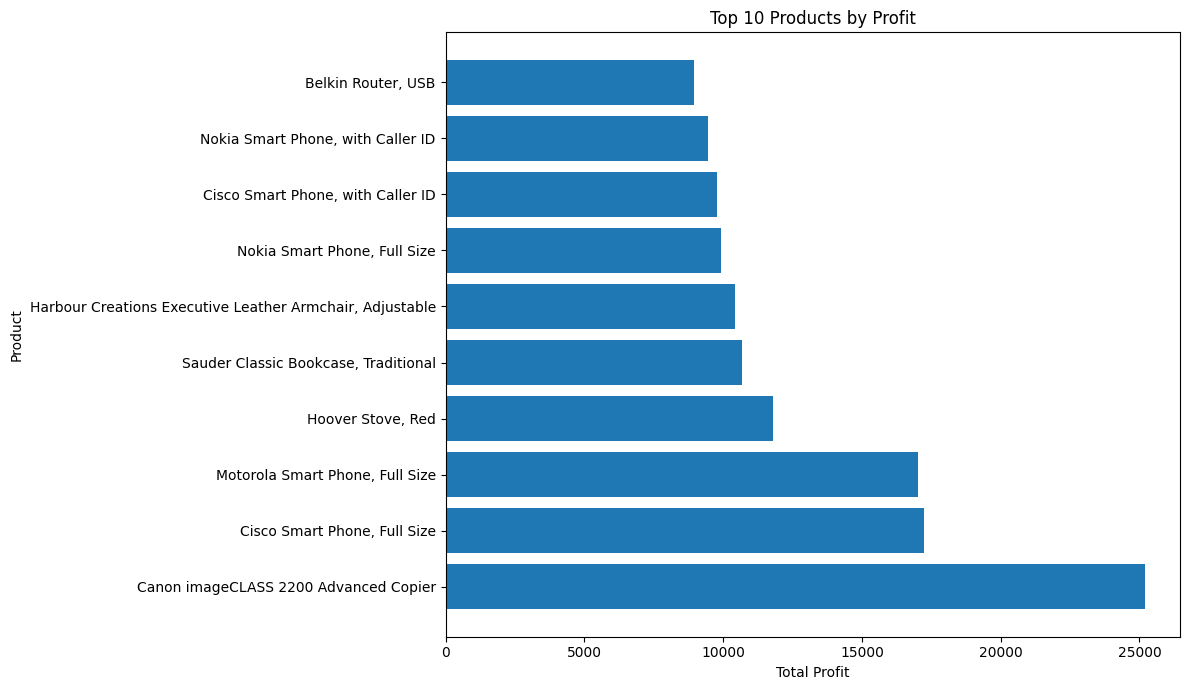

In [78]:
plt.figure(figsize=(12, 7))

plt.barh(
    top_products_profit.index,
    top_products_profit['Profit']
)

plt.title('Top 10 Products by Profit')
plt.xlabel('Total Profit')
plt.ylabel('Product')

plt.ticklabel_format(style='plain', axis='x')

plt.tight_layout()

plt.show()

### 5.9 Discount vs Profit Analysis

This analysis examines the relationship between discount levels and profitability to determine whether higher discounts negatively impact profit.

In [79]:
discount_analysis = df.groupby('Discount').agg(
    Average_Sales=('Sales', 'mean'),
    Average_Profit=('Profit', 'mean'),
    Total_Profit=('Profit', 'sum'),
    Transaction_Count=('Profit', 'count')
).sort_index()

discount_analysis

,Average_Sales,Average_Profit,Total_Profit,Transaction_Count
Discount,,,,
0.000,241.053949,61.039514,1.770695e+06,29009
0.002,567.017354,125.762649,5.797658e+04,461
0.070,810.800000,140.990022,2.114850e+04,150
0.100,388.303343,63.683426,2.590642e+05,4068
0.150,565.687616,50.602409,2.737590e+04,541
0.170,336.604082,38.317107,2.816307e+04,735
0.200,240.867347,23.552594,1.177159e+05,4998
0.202,395.439024,-14.518847,-5.952727e+02,41
0.250,444.762626,4.043371,8.005875e+02,198


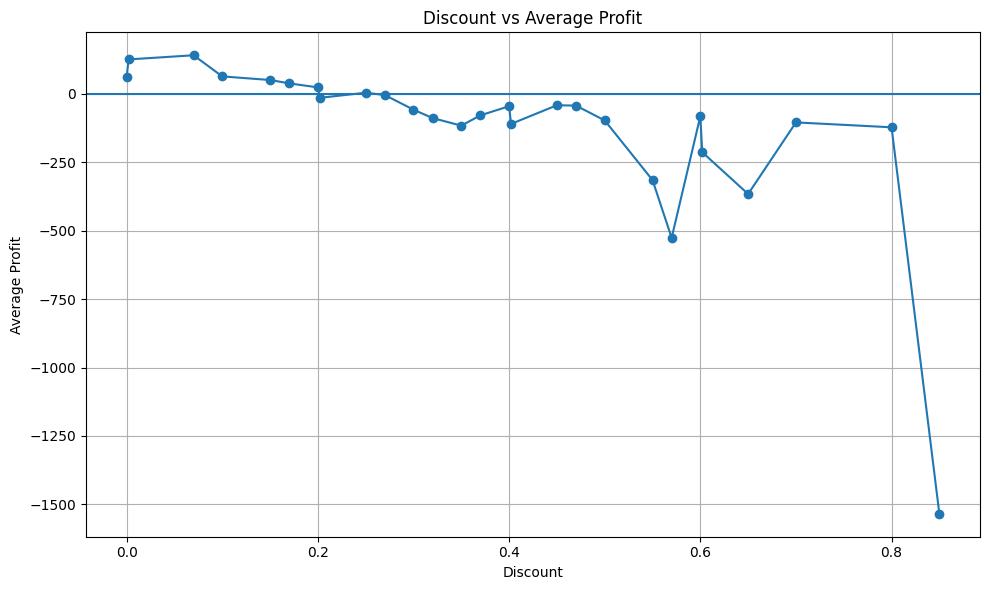

In [80]:
plt.figure(figsize=(10, 6))

plt.plot(
    discount_analysis.index,
    discount_analysis['Average_Profit'],
    marker='o'
)

plt.axhline(y=0)

plt.title('Discount vs Average Profit')
plt.xlabel('Discount')
plt.ylabel('Average Profit')

plt.grid()

plt.tight_layout()

plt.show()

In [81]:
loss_transactions = df[df['Profit'] < 0]

loss_by_discount = loss_transactions.groupby('Discount').agg(
    Loss_Transactions=('Profit', 'count'),
    Total_Loss=('Profit', 'sum'),
    Average_Loss=('Profit', 'mean')
).sort_values(
    by='Loss_Transactions',
    ascending=False
)

loss_by_discount

,Loss_Transactions,Total_Loss,Average_Loss
Discount,,,
0.400,2567,-152963.62680,-59.588479
0.600,2006,-163954.68720,-81.732147
0.700,1786,-186350.48290,-104.339576
0.500,1616,-158629.87810,-98.162053
0.200,1027,-37548.38940,-36.561236
0.100,858,-17262.91240,-20.119945
0.470,678,-31306.22580,-46.174374
0.800,316,-38616.22520,-122.203244
0.450,295,-13700.34160,-46.441836


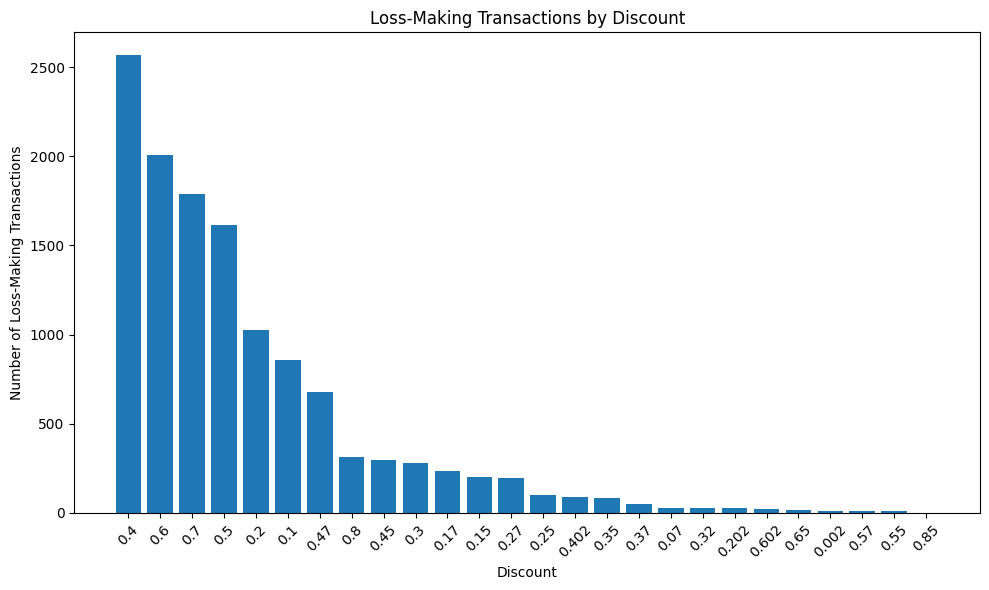

In [82]:
plt.figure(figsize=(10, 6))

plt.bar(
    loss_by_discount.index.astype(str),
    loss_by_discount['Loss_Transactions']
)

plt.title('Loss-Making Transactions by Discount')
plt.xlabel('Discount')
plt.ylabel('Number of Loss-Making Transactions')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

### 5.10 Shipping Mode Analysis

This analysis evaluates the performance of different shipping modes based on transaction count, sales, profit, and average delivery time.

In [83]:
shipping_analysis = df.groupby('Ship_Mode').agg(
    Transaction_Count=('Order_ID', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Shipping_Days=('Shipping_Days', 'mean')
).sort_values(
    by='Transaction_Count',
    ascending=False
)

shipping_analysis

,Transaction_Count,Total_Sales,Total_Profit,Average_Shipping_Days
Ship_Mode,,,,
Standard Class,30775,7578889,890596.02120,4.998018
Second Class,10309,2565747,292583.52708,3.230187
First Class,7505,1831067,208104.67520,2.181746
Same Day,2701,667202,76173.06780,0.037394


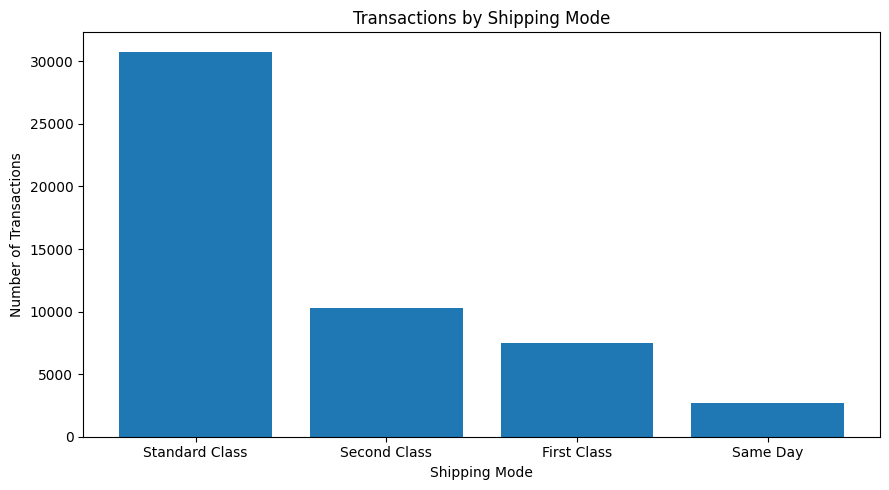

In [84]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_analysis.index,
    shipping_analysis['Transaction_Count']
)

plt.title('Transactions by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Number of Transactions')

plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()

plt.show()

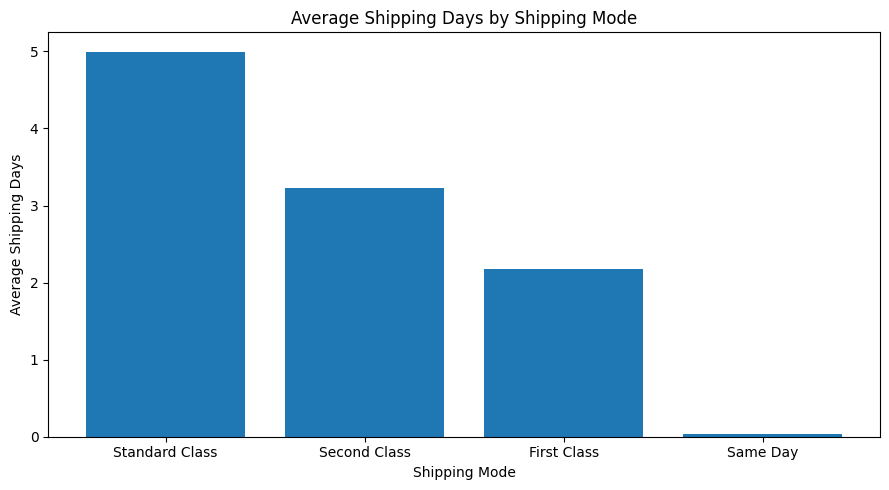

In [85]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_analysis.index,
    shipping_analysis['Average_Shipping_Days']
)

plt.title('Average Shipping Days by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Average Shipping Days')

plt.tight_layout()

plt.show()

### 5.11 Correlation Analysis

This analysis examines the relationships between key numerical variables such as Sales, Profit, Quantity, Discount, Shipping Cost, and Shipping Days.

In [87]:
correlation_columns = [
    'Sales',
    'Profit',
    'Quantity',
    'Discount',
    'Shipping_Cost',
    'Shipping_Days'
]

correlation_matrix = df[correlation_columns].corr()

correlation_matrix

,Sales,Profit,Quantity,Discount,Shipping_Cost,Shipping_Days
Sales,1.000000,0.484923,0.313580,-0.086728,0.768075,-0.004661
Profit,0.484923,1.000000,0.104365,-0.316490,0.354441,0.001745
Quantity,0.313580,0.104365,1.000000,-0.019875,0.272649,0.004347
Discount,-0.086728,-0.316490,-0.019875,1.000000,-0.079055,-0.001507
Shipping_Cost,0.768075,0.354441,0.272649,-0.079055,1.000000,-0.142823
Shipping_Days,-0.004661,0.001745,0.004347,-0.001507,-0.142823,1.000000


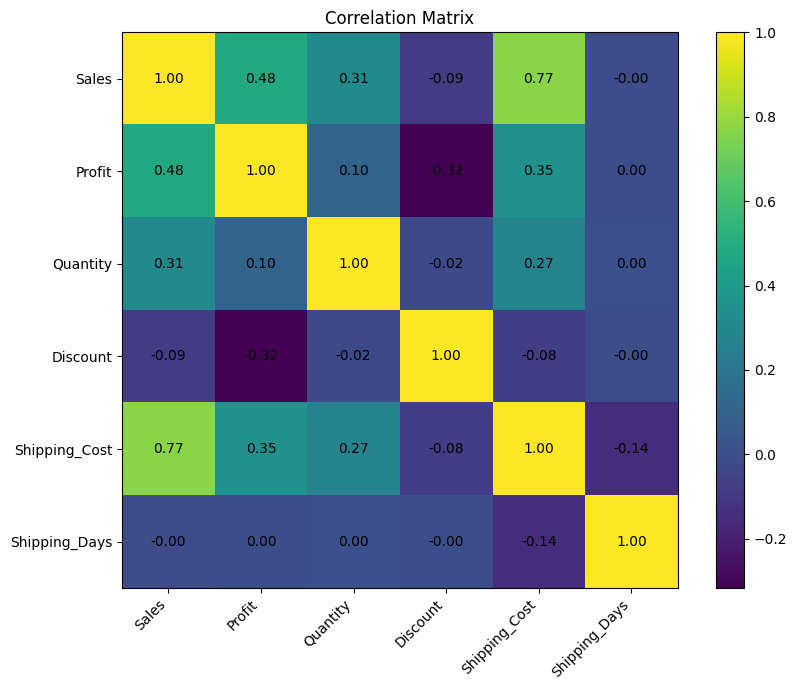

In [88]:
plt.figure(figsize=(9, 7))

plt.imshow(correlation_matrix, interpolation='nearest')

plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title('Correlation Matrix')

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j,
            i,
            f'{correlation_matrix.iloc[i, j]:.2f}',
            ha='center',
            va='center'
        )

plt.tight_layout()

plt.show()

In [89]:
df.columns.tolist()

['Category',
 'City',
 'Country',
 'Customer_ID',
 'Customer_Name',
 'Discount',
 'Market',
 'Order_Date',
 'Order_ID',
 'Order_Priority',
 'Product_ID',
 'Product_Name',
 'Profit',
 'Quantity',
 'Region',
 'Row_ID',
 'Sales',
 'Segment',
 'Ship_Date',
 'Ship_Mode',
 'Shipping_Cost',
 'State',
 'Sub_Category',
 'Market2',
 'Order_Year',
 'Order_Month',
 'Month_Name',
 'Order_Quarter',
 'Shipping_Days',
 'Profit_Margin']

In [90]:
df.to_csv(
    '../data/processed/cleaned_superstore.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## 6. Key Business Insights and Conclusion

### Key Insights

1. **Consistent Business Growth**
   - Sales increased from approximately 2.26 million in 2011 to 4.30 million in 2014.
   - Profit also increased consistently every year.

2. **Best Performing Category**
   - Technology generated the highest sales and profit among all categories.

3. **Sub-Category Performance**
   - Copiers generated the highest profit.
   - Tables were the only overall loss-making sub-category.

4. **Seasonal Sales Trend**
   - November and December generated the highest monthly sales.
   - February had the lowest sales.

5. **Regional and Market Performance**
   - Central was the highest-performing region by sales and profit.
   - APAC was the strongest market overall.

6. **Customer Insights**
   - Tom Ashbrook generated the highest sales.
   - Tamara Chand generated the highest profit.

7. **Product Insights**
   - Apple Smart Phone, Full Size generated the highest sales.
   - Canon imageCLASS 2200 Advanced Copier generated the highest profit.
   - Some high-sales products generated low or negative profit.

8. **Discount Impact**
   - Higher discounts were associated with lower profitability.
   - The 40% discount had the highest number of loss-making transactions.
   - The 70% discount generated the highest total loss.

9. **Shipping Insights**
   - Standard Class was the most frequently used shipping mode.
   - It generated the highest sales and profit.
   - Shipping duration showed little linear relationship with sales or profit.

10. **Correlation Analysis**
    - Sales and Shipping Cost showed a strong positive correlation.
    - Discount and Profit showed a negative correlation.
    - Sales and Profit showed a moderate positive correlation.

### Conclusion

The analysis shows consistent business growth between 2011 and 2014. Technology, APAC, and the Central region were among the strongest business performers. However, high discount levels were associated with significant losses, highlighting the need to review discount strategies.

The analysis also demonstrates that high sales do not always result in high profit. Therefore, future business decisions should consider profitability alongside revenue when evaluating products, customers, regions, and discount strategies.

In [91]:
df.to_csv(
    '../data/processed/cleaned_superstore_utf8.csv',
    index=False,
    encoding='utf-8-sig'
)

print("UTF-8 dataset saved successfully!")

UTF-8 dataset saved successfully!
